In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

### UECの時系列データ取得

In [3]:
code = 'UEC'
market = None
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')

response = request_api.update_stock_timeseries_data(
    code=code,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
timeseries_df = request_api.get_stock_time_series_data(
    code=code,
    market=market,
    start=start,
    end=end
)
timeseries_df

取得件数: 4911


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1124429,UEC,None,2007-04-05,6.97,6.98,6.27,6.65,641100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1124430,UEC,None,2007-04-09,7.30,7.35,7.02,7.05,655400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1124431,UEC,None,2007-04-10,7.15,7.39,6.92,7.10,727400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1124432,UEC,None,2007-04-11,7.16,7.31,7.08,7.15,292100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1124433,UEC,None,2007-04-12,6.65,7.17,6.62,7.16,465700,7.022,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4906,1129335,UEC,None,2026-10-06,10.11,10.39,9.59,9.67,16233500,9.516,...,9.576563,-19.653377,False,NaN,NaN,NaN,NaN,NaN,NaN,True
4907,1148487,UEC,None,2026-10-07,9.47,9.83,9.39,9.75,8959200,9.572,...,9.528731,-26.116281,False,NaN,NaN,NaN,NaN,NaN,NaN,True
4908,1160627,UEC,None,2026-10-08,9.14,9.49,9.00,9.39,10898600,9.572,...,9.462523,-33.650645,False,NaN,NaN,NaN,NaN,NaN,NaN,True
4909,1187723,UEC,None,2026-10-09,9.19,9.34,9.11,9.34,6442500,9.506,...,9.408353,-41.727141,False,NaN,NaN,-0.436437,NaN,NaN,NaN,False


### Sprott Physical Uranium Trust Fundの時系列データを取得

Yahoo financeはウランスポット価格に関する時系列データを提供していないためSprottのETFで代替

In [5]:
uran = 'U-UN'
uran_market_code = 'TO'

response = request_api.update_stock_timeseries_data(
    code=uran,
    market=uran_market_code,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
uran_timeseries_df = request_api.get_stock_time_series_data(
    code=uran,
    market=uran_market_code,
    start=start,
    end=end
)
uran_timeseries_df

取得件数: 5126


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1129336,U-UN,TO,2006-05-09,9.050000,9.140000,8.600000,9.140000,518800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1129337,U-UN,TO,2006-05-10,9.400000,9.470000,9.060000,9.060000,493600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1129338,U-UN,TO,2006-05-11,9.140000,9.500000,9.110000,9.500000,1065200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1129339,U-UN,TO,2006-05-12,8.850000,9.140000,8.710000,9.140000,460300,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1129340,U-UN,TO,2006-05-15,8.400000,9.000000,8.380000,8.850000,519800,9.138,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5121,1134457,U-UN,TO,2026-10-05,27.200001,27.420000,27.100000,27.160000,505200,26.788,...,26.724248,32.177922,False,NaN,NaN,NaN,NaN,NaN,NaN,True
5122,1134458,U-UN,TO,2026-10-06,28.139999,28.360001,27.410000,27.469999,1412700,26.990,...,26.748975,29.556903,False,NaN,NaN,-0.087162,NaN,NaN,NaN,False
5123,1153611,U-UN,TO,2026-10-07,27.660000,28.080000,27.330000,27.959999,1354000,27.264,...,26.742523,28.626313,True,27.264,NaN,NaN,NaN,NaN,NaN,False
5124,1165752,U-UN,TO,2026-10-08,26.600000,27.510000,26.430000,27.510000,1422800,27.448,...,26.742715,26.726714,True,NaN,NaN,NaN,NaN,NaN,NaN,False


In [7]:
def stock_prices_and_material_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        market: str | None =  None,
        df_sp: pd.DataFrame | None = None,
        df_mat1: pd.DataFrame | None = None,
        df_mat2: pd.DataFrame | None = None
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=market,
        start=start,
        end=end,
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # mat1価格を統合
    if df_mat1 is not None:
        df_mat1_tmp = df_mat1.copy() if df_mat1 is not None else pd.DataFrame()
        if "date" not in df_mat1_tmp.columns:
            df_mat1_tmp = df_mat1_tmp.reset_index()
        df_mat1_tmp["date"] = pd.to_datetime(df_mat1_tmp["date"])
        df_mat1_tmp = df_mat1_tmp.set_index("date")
        df_mat1_tmp = df_mat1_tmp.loc[start:end]

    # mat2価格を統合
    if df_mat2 is not None:
        df_mat2_tmp = df_mat2.copy() if df_mat2 is not None else pd.DataFrame()
        if "date" not in df_mat2_tmp.columns:
            df_mat2_tmp = df_mat2_tmp.reset_index()
        df_mat2_tmp["date"] = pd.to_datetime(df_mat2_tmp["date"])
        df_mat2_tmp = df_mat2_tmp.set_index("date")
        df_mat2_tmp = df_mat2_tmp.loc[start:end]

    # 金価格
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_mat1 is not None:
        df["MA50_MAT1"] = df_mat1_tmp["ma50"].reindex(df.index)
        df["MA200_MAT1"] = df_mat1_tmp["ma200"].reindex(df.index)
    if df_mat2 is not None:
        df["MA50_MAT2"] = df_mat2_tmp["ma50"].reindex(df.index)
        df["MA200_MAT2"] = df_mat2_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / GOLD",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- MAT1（右軸） ---
    if df_mat1 is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_MAT1"],
                name="MAT1_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_MAT1"],
                name="MAT1_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- MAT2（左軸） ---
    if df_mat2 is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_MAT2"],
                name="MAT2_MA50",
                line={"color": "gray", "width": 1.2},
                yaxis="y"   # ★ 左軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_MAT2"],
                name="MAT2_MA200",
                line={"color": "black", "width": 1.2},
                yaxis="y"   # ★ 左軸
            )
        )

    return fig

In [8]:
name = "Uranium Energy Corp."
start = dt.datetime(2025, 12, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_material_prices(
    code=code,
    name=name,
    start=start,
    end=end,
    market=None,
    df_sp=None,
    df_mat1=None,
    df_mat2=None
)
fig.show()

取得件数: 424


In [9]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{code}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/UEC_2025-12-01_2026-10-13.png


In [10]:
name = "Sprott Physical Uranium Trust Fund"
start = dt.datetime(2025, 12, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_material_prices(
    code=uran,
    name=name,
    start=start,
    end=end,
    market=uran_market_code,
    df_sp=None,
    df_mat1=None,
    df_mat2=None
)
fig.show()

取得件数: 423


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"SPUT_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/SPUT_2025-12-01_2026-10-13.png


#### 時系列データを保存

In [12]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{code}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,4716,1129145,UEC,None,13.11,13.24,11.90,11.95,9206800,12.058,...,11.801687,-43.588321,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,4717,1129146,UEC,None,13.99,14.14,13.17,13.57,10467100,12.294,...,11.832961,-35.622812,False,NaN,NaN,-0.067753,NaN,NaN,NaN,False
2026-01-06,4718,1129147,UEC,None,14.54,14.59,13.46,14.08,10755000,12.710,...,11.857709,-26.692564,True,12.71,NaN,NaN,NaN,11.666667,NaN,False
2026-01-07,4719,1129148,UEC,None,14.42,14.56,13.95,14.26,8957600,13.106,...,11.896822,-20.221122,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,4720,1129149,UEC,None,14.57,14.63,14.13,14.40,6613500,13.652,...,11.967161,-12.353795,True,NaN,NaN,NaN,NaN,NaN,NaN,False


{'fib_levels_down': {'1.000': np.float64(8.8100004196167),
  '1.272': np.float64(6.628560554504395),
  '1.382': np.float64(5.746360609054566),
  '1.618': np.float64(3.853640726089478)},
 'fib_levels_up': {'1.272': np.float64(19.01143978881836),
  '1.382': np.float64(19.893639734268188),
  '1.618': np.float64(21.786359617233277),
  '2.000': np.float64(24.84999942779541)},
 'swing_high': np.float64(16.829999923706055),
 'swing_low': np.float64(8.8100004196167),
 'df_with_fib':           date  index       id stock_code stock_market   open   high    low  \
 0   2026-01-02   4716  1129145        UEC         None  13.11  13.24  11.90   
 1   2026-01-05   4717  1129146        UEC         None  13.99  14.14  13.17   
 2   2026-01-06   4718  1129147        UEC         None  14.54  14.59  13.46   
 3   2026-01-07   4719  1129148        UEC         None  14.42  14.56  13.95   
 4   2026-01-08   4720  1129149        UEC         None  14.57  14.63  14.13   
 ..         ...    ...      ...        ..

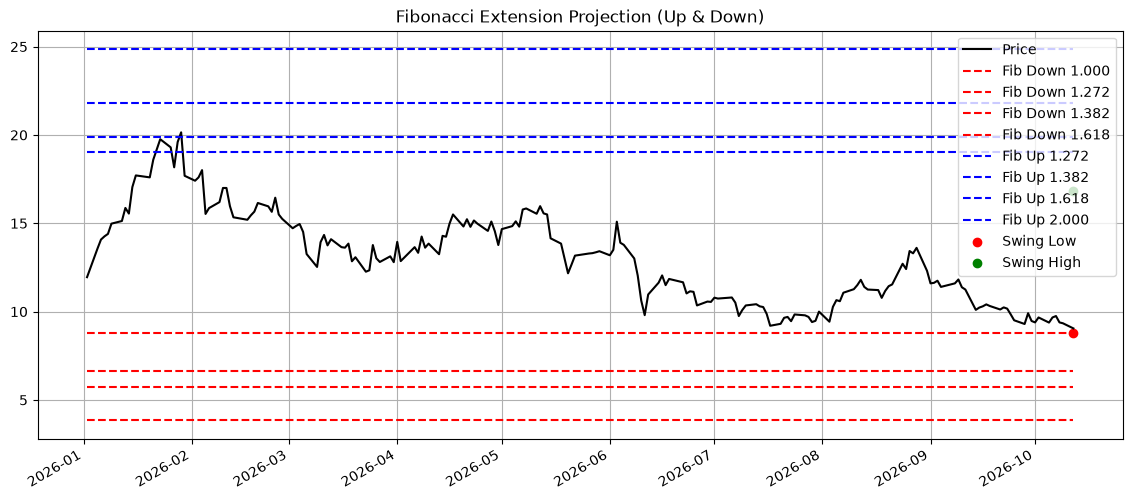

In [13]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [14]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{code}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")